# P11 — Subconjuntos naive e memória (Tcm/Tem): resolução, nomes pela NMF e helpers (Th1, Th2…)

**O que faz.** Repete o P10 em dois subconjuntos das CD4 limpas do P09:

- **naive:** a `anotacao` "CD4 naive";
- **memória (Tcm/Tem):** o `grupo` "CD4 memória" da 1ª rodada, isto é, transição naive/Tcm, Tcm,
  Tcm/Tfh, Th17 e Tem GZMK⁺.

Para cada um:

1. refaz HVG, ComBat, PCA, grafo e UMAP só no subconjunto ([functions/subset.py](../functions/subset.py));
2. varre a resolução (5 sementes). A regra é fixada antes dos nomes e é a mesma do P10: maior ARI
   médio entre sementes, entre as resoluções com pelo menos K clusters. K é o número de tipos do
   atlas L2 com ≥ 5 % das células do subconjunto; nas Treg do P10, K = 3;
3. compara os clusters com a NMF: o atlas L2 de Yasumizu et al. 2024 e a NMF k = 14 da 1ª rodada;
4. nomeia cada cluster misturando o atlas (NMF) e os marcadores, com a regra de cada subconjunto
   abaixo.

**Sufixo de helper (memória).** O cluster recebe "(Th1)", "(Th2)", "(Th17)" ou "(Tfh)" quando
duas fontes concordam:
- os tipos do atlas daquele helper somam ≥ 25 % do cluster;
- o escore de marcadores daquele helper está acima da média dos clusters do subconjunto (z > 0).

Com mais de um helper que passe, fica o de maior fração no atlas.

**Saída.** A coluna `anotacaoSubset` de todas as CD4 limpas:
- estados de Treg do P10;
- naive e memória daqui;
- os demais tipos (ativada, ativada Th17, citotóxica) mantêm a `anotacao`.

**Limite.** 7 pacientes; MB e NP com um paciente cada.

In [1]:
import sys
sys.path.insert(0, "/mnt/SATA/singleCellTaru/src/Reseq")

import warnings
warnings.filterwarnings("ignore")

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import scipy.sparse as sp
from IPython.display import display

from functions import config, fmt as F, io, plotting
from functions import anotacao as an
from functions import subset as SB
from functions.issues import IssueLog, show

plotting.apply_style()
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 40)
sc.settings.verbosity = 0
plt.rcParams["savefig.bbox"] = "tight"

NB = "P11_naive_memoria_subset"
log = IssueLog(NB)
INK = plotting.INK
RES = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.8, 1.0, 1.2, 1.5]
SEEDS = (0, 1, 2, 3, 4)

# helpers: tipos do atlas L2 e painel de marcadores
HELPER_ATLAS = {"Th1": ["TemTh1", "TemTh1pre", "TemraTh1"], "Th2": ["TcmTh2"], "Th17": ["TcmTh17", "TemTh117"],
                "Tfh": ["TcmTfh", "TemTph"]}
HELPER_GENES = {"Th1": ["TBX21", "CXCR3", "IFNG", "IL12RB2", "CCR5"], "Th2": ["GATA3", "CCR4", "PTGDR2", "IL4R", "HPGDS"],
                "Th17": ["RORC", "CCR6", "KLRB1", "IL23R", "RORA"], "Tfh": ["CXCR5", "PDCD1", "BCL6", "MAF", "TOX2"]}
# estados naive do atlas e painéis
NAIVE_ATLAS = {"ativada": "TnaiveAct", "IFN⁺": "TnaiveMX1", "emigrante tímica (SOX4⁺)": "TnaiveSOX4"}
NAIVE_GENES = {"ativada": ["CD69", "NFKBIA", "MIR155HG", "TNFAIP3", "IER2", "JUNB"],
               "IFN⁺": ["IFIT3", "MX1", "ISG15", "RSAD2", "IFI6", "OAS1"],
               "emigrante tímica (SOX4⁺)": ["SOX4", "PECAM1", "CR2", "TOX", "IKZF2"]}
MEM_GENES = {"memória central": ["CCR7", "SELL", "LEF1", "TCF7"], "efetora": ["GZMK", "CCL5", "S100A4", "ANXA1", "KLRB1"]}

In [2]:
cd4 = SB.carregar_cd4()
N_CD4 = cd4.n_obs
SUBS = {"naive": (cd4.obs["anotacao"] == "CD4 naive").to_numpy(),
        "memória": (cd4.obs["grupo"] == "CD4 memória").to_numpy()}
for k, m in SUBS.items():
    print(f"{k}: {F.n(m.sum())} células; anotação: {cd4.obs.loc[m, 'anotacao'].value_counts().to_dict()}")


def analisar(nome: str, mask) -> dict:
    """Reprocessa, varre resoluções e devolve o subconjunto com os clusters da resolução escolhida."""
    sub = cd4[mask].copy()
    b, info = SB.reprocessar(sub)
    at = b.obs["atlas_L2"].astype(object)
    frac = at.value_counts(normalize=True)
    k_min = max(2, int((frac >= 0.05).sum()))
    refs = {"atlas L2": at, "NMF k=14": b.obs["nmf14_rotulo"].astype(object)}
    sw, estab = SB.varrer(b, RES, seeds=SEEDS, referencias=refs)
    cand = estab[estab["clusters"] >= k_min]
    r = float(cand["ARI entre sementes (média)"].idxmax())
    cl = sw[f"leiden_r{r:g}_s0"].astype(str).to_numpy()
    b.obs["cluster"] = pd.Categorical(cl, categories=sorted(set(cl), key=int))
    slug = "naive" if nome == "naive" else "memoria"
    io.save_table(estab, NB, f"estabilidade_{slug}", description=f"{nome}: clusters, estabilidade e ARI com a NMF por resolução")
    print(f"{nome}: {F.n(b.n_obs)} células; K = {k_min} (tipos do atlas com ≥ 5 %); resolução escolhida {F.f(r, 1)} "
          f"({estab.loc[r, 'clusters']} clusters, ARI entre sementes {F.f(estab.loc[r, 'ARI entre sementes (média)'], 2)}); "
          f"bibliotecas fora das HVG: {info['bibliotecas_fora_das_hvg']}")
    display(estab.round(3))
    return {"b": b, "info": info, "estab": estab, "res": r, "k_min": k_min, "slug": slug}


def fig_resolucao(R, nome):
    estab, r = R["estab"], R["res"]
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(12.5, 4.2))
    cor = plotting.OLD_NEW_COLORS["nova"]
    a1.plot(RES, estab["clusters"], "-o", color=cor, lw=2, ms=7, mec=INK["surface"], mew=1.2)
    a1.axhline(R["k_min"], color=INK["axis"], lw=1, ls=(0, (1, 2)))
    a1.set_ylabel("clusters (semente 0)")
    a1.set_title("Número de clusters", loc="left")
    a2.fill_between(RES, estab["ARI entre sementes (mínimo)"], estab["ARI entre sementes (média)"], color=cor, alpha=0.15, lw=0)
    a2.plot(RES, estab["ARI entre sementes (média)"], "-o", color=cor, lw=2, ms=7, mec=INK["surface"], mew=1.2,
            label="ARI entre sementes (média; faixa até o mínimo)")
    a2.plot(RES, estab["ARI com atlas L2"], "-s", color=plotting.OLD_NEW_COLORS["antiga"], lw=2, ms=6, mec=INK["surface"],
            mew=1.2, label="ARI com o atlas L2")
    a2.set_ylim(0, 1.02)
    a2.set_title("Estabilidade e concordância com a NMF", loc="left")
    a2.legend(loc="upper right", frameon=False, fontsize=8.5)
    for ax in (a1, a2):
        ax.axvline(r, color=INK["axis"], lw=1, ls=(0, (4, 3)), zorder=0)
        ax.set_xlabel("resolução do Leiden")
        ax.set_xticks(RES)
        ax.set_xticklabels([F.f(x, 1) for x in RES], fontsize=8)
    plotting.decimals(a2, "y", 1)
    plotting.note(fig, f"{F.n(R['b'].n_obs)} células ({nome}) · {plotting.N_DESIGN}. Cinco sementes por resolução. Tracejado: a "
                       f"escolhida (maior ARI entre sementes com ≥ {R['k_min']} clusters, linha pontilhada).", y=0.0)
    fig.tight_layout(rect=(0, 0.03, 1, 1))
    plotting.savefig(fig, NB, f"resolucao_{R['slug']}", description=f"{nome}: clusters e estabilidade por resolução",
                     data=estab.reset_index(), data_index=False)
    plt.show()


def fig_umap_dot(R, nome, genes, ordem_nomes):
    b = R["b"]
    b.obs["estimulo"] = pd.Categorical(b.obs["estimulo"].astype(str))
    b.uns["estimulo_colors"] = [plotting.STIMULATION_COLORS["estimulado"] if c == "estimulado"
                                else plotting.STIMULATION_COLORS["nao_estimulado"] for c in b.obs["estimulo"].cat.categories]
    fig, axes = plt.subplots(1, 4, figsize=(24, 5.6))
    for ax, (col, tit) in zip(axes, [("anotacaoSubset", "anotacaoSubset"), ("cluster", f"cluster (resolução {F.f(R['res'], 1)})"),
                                     ("atlas_L2", "atlas L2 (NMF de Yasumizu)"), ("estimulo", "estímulo")]):
        if col == "atlas_L2":
            b.obs["atlas_L2_cat"] = pd.Categorical(b.obs["atlas_L2"].astype(str))
            col = "atlas_L2_cat"
        sc.pl.umap(b, color=col, ax=ax, show=False, frameon=False, size=4, title=tit)
    plotting.note(fig, f"{F.n(b.n_obs)} células ({nome}) · {plotting.N_DESIGN}. UMAP do ComBat refeito só no subconjunto.", y=0.0)
    fig.tight_layout(rect=(0, 0.03, 1, 1))
    plotting.savefig(fig, NB, f"umap_{R['slug']}", description=f"UMAP ({nome}): nome final, cluster, atlas L2 e estímulo",
                     data=pd.DataFrame({"cell_key": b.obs["cell_key"].astype(str).to_numpy(),
                                        "cluster": b.obs["cluster"].astype(str).to_numpy(),
                                        "anotacaoSubset": b.obs["anotacaoSubset"].astype(str).to_numpy(),
                                        "umap1": b.obsm["X_umap"][:, 0], "umap2": b.obsm["X_umap"][:, 1]}), data_index=False)
    plt.show()
    genes = [g for g in genes if g in b.var_names]
    grupos = b.obs["cluster"].astype(str) + " · " + b.obs["anotacaoSubset"].astype(str)
    frac, mean = an.dot_stats(b, grupos, genes)
    ordem = sorted(frac.index, key=lambda s: (ordem_nomes.index(s.split(" · ", 1)[1]) if s.split(" · ", 1)[1] in ordem_nomes else 99,
                                              int(s.split(" · ")[0])))
    n_g = grupos.value_counts()
    fig, ax = plt.subplots(figsize=(max(10, 0.32 * len(genes) + 5), 0.42 * len(ordem) + 2.6))
    sc_ = an.dotplot(ax, frac, mean, rows=ordem, cols=genes)
    ax.set_yticklabels([f"{g} (n={F.n(n_g[g])})" for g in ordem])
    cb = fig.colorbar(sc_, ax=ax, fraction=0.03, pad=0.01)
    cb.set_label("média escalonada por gene")
    plotting._style_colorbar(cb)
    for v in (0.25, 0.5, 1.0):
        ax.scatter([], [], s=v * 120, c=INK["muted"], label=F.pct(v, 0))
    ax.legend(title="detectam", loc="upper left", bbox_to_anchor=(1.08, 1.0), frameon=False, labelspacing=1.2)
    plotting.note(fig, f"{F.n(b.n_obs)} células ({nome}) · {plotting.N_DESIGN}. Linhas = cluster · nome final. "
                       "Detecção nas contagens do SoupX; média na lognorm.", y=0.0)
    fig.tight_layout()
    plotting.savefig(fig, NB, f"dotplot_{R['slug']}", description=f"Marcadores por cluster ({nome})",
                     data=(frac * 100).round(1).reindex(ordem).rename_axis("cluster").reset_index(), data_index=False)
    plt.show()

naive: 11.759 células; anotação: {'CD4 naive': 11759}
memória: 12.965 células; anotação: {'CD4 Tcm': 4968, 'CD4 Tcm/Tfh': 3086, 'CD4 transição naive/Tcm': 2696, 'CD4 Th17': 2159, 'CD4 Tem GZMK⁺': 56}


## 1. Naive

**Regra dos nomes.** O atlas divide a naive em quatro estados: Tnaive, TnaiveAct (ativada),
TnaiveMX1 (resposta a interferon) e TnaiveSOX4 (emigrante tímica recente). A NMF k = 14 separa a
"CD4 naive IFN⁺". Um cluster recebe um estado quando:
- a fração desse estado no atlas é ≥ 30 % (para IFN⁺ vale também a NMF "CD4 naive IFN⁺" ≥ 30 %);
- o escore de marcadores do estado está acima da média dos clusters (z > 0).

Sem estado que passe, o cluster é "CD4 naive".

naive: 11.759 células; K = 3 (tipos do atlas com ≥ 5 %); resolução escolhida 1,0 (9 clusters, ARI entre sementes 0,65); bibliotecas fora das HVG: {}


,clusters,clusters por semente,ARI entre sementes (média),ARI entre sementes (mínimo),células em clusters estáveis,menor cluster,ARI com atlas L2,ARI com NMF k=14
resolução,,,,,,,,
0.1,1,1 / 1 / 1 / 1 / 1,1.000,1.000,1.000,11759,0.000,0.000
0.2,2,2 / 2 / 2 / 2 / 2,0.505,0.260,0.610,4585,0.021,0.131
0.3,3,3 / 4 / 3 / 3 / 3,0.551,0.310,0.559,119,0.027,0.103
0.4,4,4 / 4 / 5 / 4 / 4,0.614,0.355,0.314,124,0.116,0.150
0.5,5,5 / 4 / 5 / 5 / 4,0.601,0.413,0.454,161,0.115,0.124
0.6,6,6 / 5 / 6 / 6 / 5,0.593,0.411,0.426,56,0.118,0.095
0.8,7,7 / 9 / 8 / 8 / 7,0.631,0.419,0.543,39,0.099,0.071
1.0,9,9 / 9 / 8 / 8 / 10,0.649,0.480,0.722,49,0.094,0.053
1.2,11,11 / 11 / 11 / 10 / 11,0.510,0.408,0.027,69,0.074,0.029


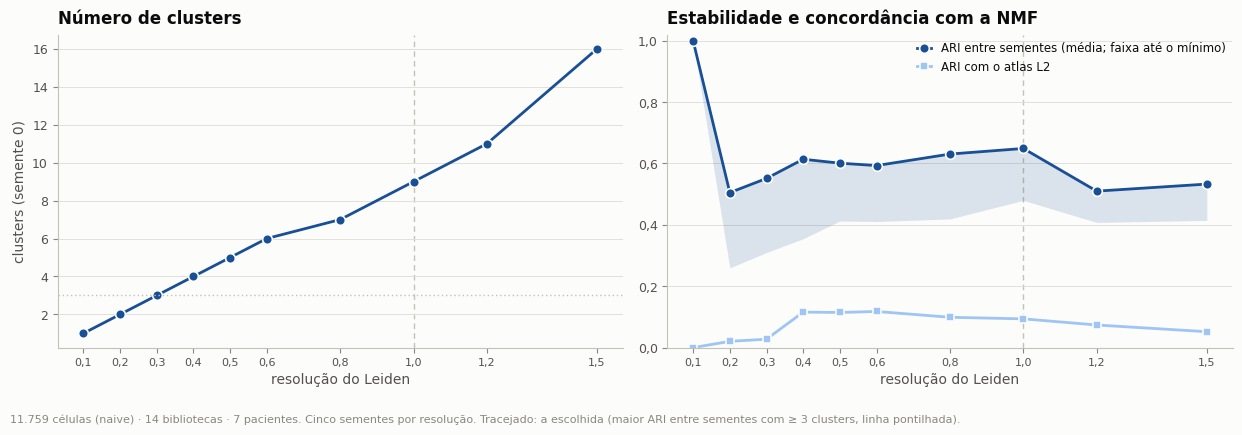

In [3]:
RN = analisar("naive", SUBS["naive"])
fig_resolucao(RN, "naive")

In [4]:
b = RN["b"]
cl = b.obs["cluster"].astype(str).to_numpy()
CL = list(b.obs["cluster"].cat.categories)
comp_at = SB.composicao(cl, b.obs["atlas_L2"]).reindex(CL).fillna(0)
comp_nmf = SB.composicao(cl, b.obs["nmf14_rotulo"]).reindex(CL).fillna(0)
esc = SB.escores(b, NAIVE_GENES, cl).reindex(CL)
z = (esc - esc.mean()) / esc.std(ddof=0)
nomes = {}
for c in CL:
    passa = {}
    for est, tipo in NAIVE_ATLAS.items():
        f_at = comp_at.loc[c].get(tipo, 0.0)
        if est == "IFN⁺":
            f_at = max(f_at, comp_nmf.loc[c].get("CD4 naive IFN⁺", 0.0))
        if f_at >= 0.30 and z.loc[c, est] > 0:
            passa[est] = f_at
    nomes[c] = f"CD4 naive {max(passa, key=passa.get)}" if passa else "CD4 naive"
b.obs["anotacaoSubset"] = pd.Categorical(pd.Series(cl).map(nomes).to_numpy())
tab = pd.concat([pd.Series(cl).value_counts().reindex(CL).rename("células"),
                 pd.Series(b.obs["estimulo"].astype(str).to_numpy() == "estimulado").groupby(cl).mean().reindex(CL).rename("fração ML"),
                 comp_at[[t for t in ["Tnaive", *NAIVE_ATLAS.values()] if t in comp_at]].add_prefix("atlas "),
                 comp_nmf[[t for t in ["CD4 naive", "CD4 naive IFN⁺", "CD4 transição naive/Tcm"] if t in comp_nmf]].add_prefix("NMF "),
                 z.add_prefix("z "), pd.Series(nomes).rename("nome")], axis=1)
io.save_table(tab, NB, "clusters_naive", description="Naive: composição pelo atlas e pela NMF, escores z e nome de cada cluster")
display(tab.round(2))
RN["nomes"] = nomes

,células,fração ML,atlas Tnaive,atlas TnaiveAct,atlas TnaiveMX1,atlas TnaiveSOX4,NMF CD4 naive,NMF CD4 naive IFN⁺,NMF CD4 transição naive/Tcm,z ativada,z IFN⁺,z emigrante tímica (SOX4⁺),nome
0,2937,0.54,0.73,0.15,0.06,0.04,0.92,0.00,0.00,-0.74,-0.46,-0.35,CD4 naive
1,2562,0.59,0.78,0.12,0.03,0.02,0.64,0.03,0.27,1.99,-0.09,-0.35,CD4 naive
2,2431,0.53,0.74,0.13,0.04,0.06,0.91,0.00,0.00,-0.05,-0.50,-0.33,CD4 naive
3,1540,0.63,0.28,0.05,0.65,0.00,0.54,0.39,0.02,0.14,2.61,-0.39,CD4 naive IFN⁺
4,1148,0.86,0.29,0.49,0.18,0.00,0.68,0.13,0.01,-0.80,0.57,-0.43,CD4 naive
5,490,0.43,0.81,0.08,0.03,0.01,0.70,0.03,0.02,0.83,-0.35,-0.18,CD4 naive
6,301,0.25,0.57,0.38,0.02,0.02,0.96,0.00,0.00,-0.43,-0.69,-0.42,CD4 naive
7,301,0.55,0.47,0.17,0.07,0.00,0.71,0.03,0.02,0.64,-0.23,-0.36,CD4 naive
8,49,0.35,0.15,0.02,0.00,0.83,0.94,0.00,0.00,-1.60,-0.86,2.82,CD4 naive emigrante tímica (SOX4⁺)


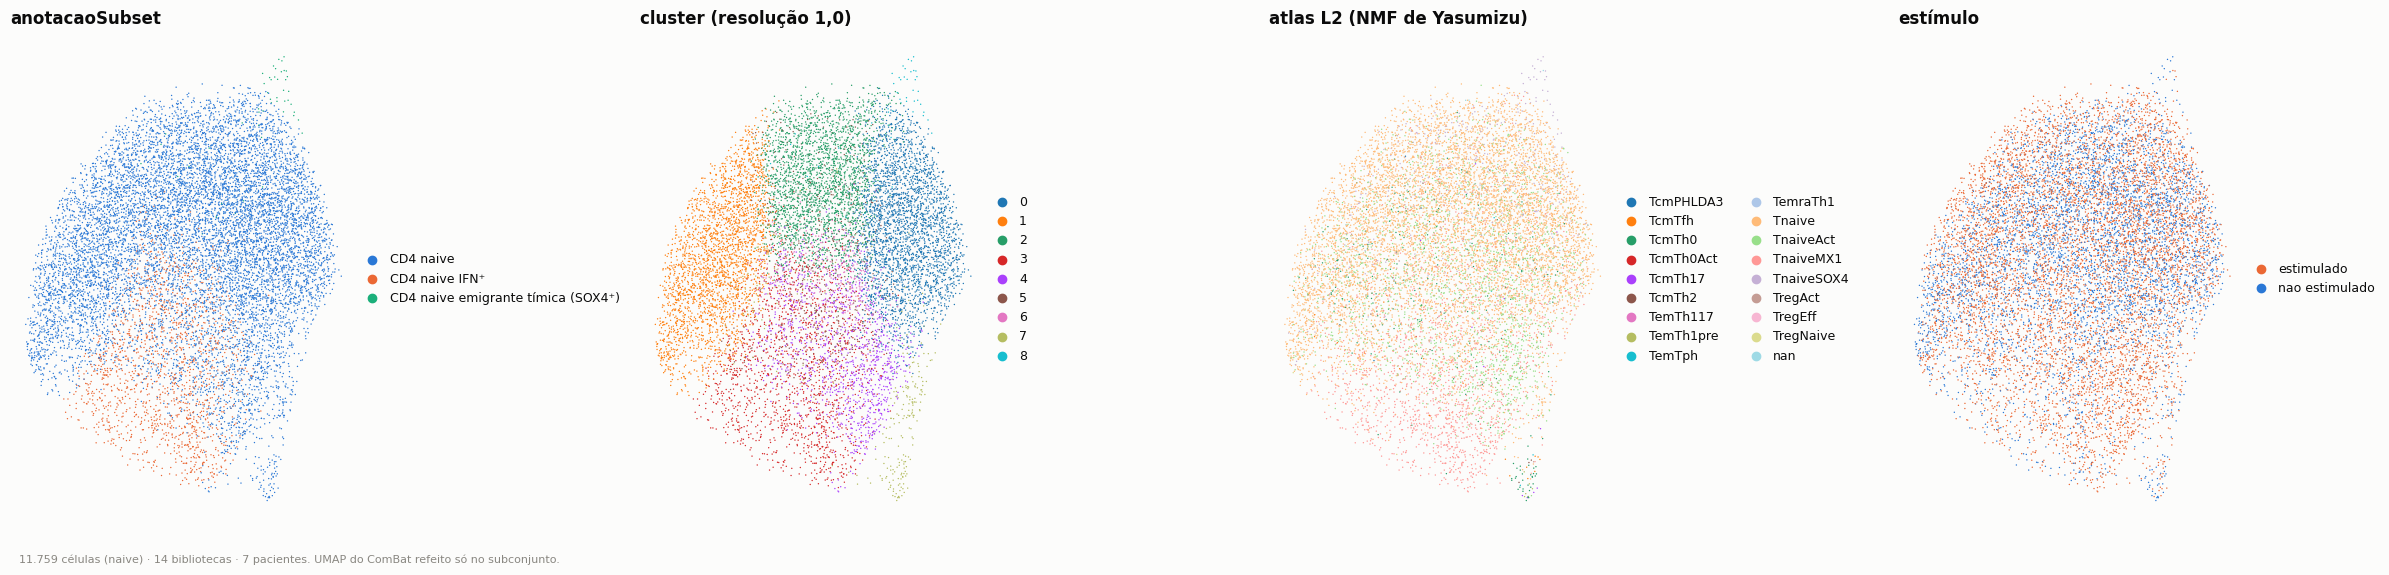

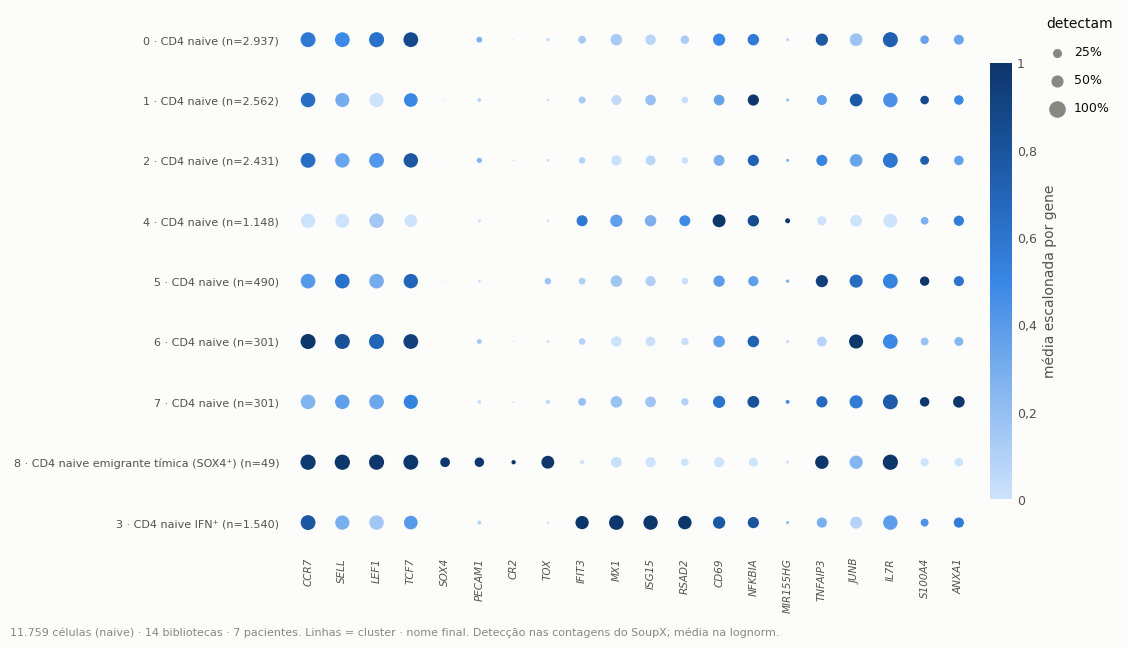

In [5]:
ORD_N = ["CD4 naive", "CD4 naive emigrante tímica (SOX4⁺)", "CD4 naive IFN⁺", "CD4 naive ativada"]
fig_umap_dot(RN, "naive", ["CCR7", "SELL", "LEF1", "TCF7", "SOX4", "PECAM1", "CR2", "TOX", "IFIT3", "MX1", "ISG15", "RSAD2",
                           "CD69", "NFKBIA", "MIR155HG", "TNFAIP3", "JUNB", "IL7R", "S100A4", "ANXA1"], ORD_N)

## 2. Memória (Tcm/Tem)

**Regra dos nomes.**
- **Prefixo:** a categoria do atlas mais frequente no cluster. Tnaive* (incluindo TnaiveMX1 etc.)
  dá "CD4 transição naive/Tcm"; Tcm* dá "CD4 Tcm"; Tem* dá "CD4 Tem"; Temra* dá "CD4 Temra".
- **Sufixo:** o helper, pela regra do cabeçalho: atlas ≥ 25 % e z do painel > 0.
- **IFN⁺:** se a NMF "CD4 naive IFN⁺" ou o atlas TnaiveMX1 passar de 30 %, o cluster ganha
  "IFN⁺" antes do sufixo.

memória: 12.965 células; K = 5 (tipos do atlas com ≥ 5 %); resolução escolhida 0,4 (5 clusters, ARI entre sementes 0,60); bibliotecas fora das HVG: {}


,clusters,clusters por semente,ARI entre sementes (média),ARI entre sementes (mínimo),células em clusters estáveis,menor cluster,ARI com atlas L2,ARI com NMF k=14
resolução,,,,,,,,
0.1,2,2 / 3 / 2 / 2 / 2,0.694,0.416,1.000,2621,0.007,0.115
0.2,2,2 / 3 / 3 / 3 / 3,0.655,0.326,1.000,2755,0.006,0.120
0.3,5,5 / 4 / 5 / 4 / 5,0.507,0.366,0.335,53,0.084,0.367
0.4,5,5 / 5 / 7 / 6 / 6,0.598,0.407,0.327,53,0.084,0.246
0.5,7,7 / 6 / 7 / 7 / 7,0.527,0.382,0.332,53,0.090,0.348
0.6,8,8 / 7 / 8 / 7 / 8,0.533,0.429,0.004,53,0.089,0.304
0.8,10,10 / 11 / 10 / 10 / 11,0.549,0.432,0.135,53,0.099,0.291
1.0,12,12 / 12 / 11 / 13 / 13,0.550,0.451,0.119,54,0.106,0.295
1.2,15,15 / 15 / 13 / 15 / 15,0.583,0.523,0.114,58,0.112,0.252


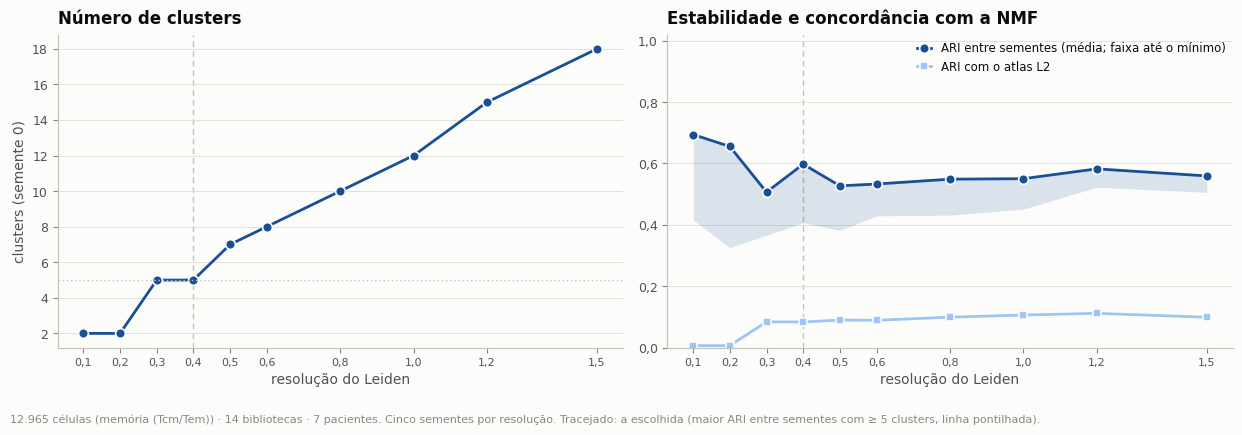

In [6]:
RM = analisar("memória", SUBS["memória"])
fig_resolucao(RM, "memória (Tcm/Tem)")

In [7]:
b = RM["b"]
cl = b.obs["cluster"].astype(str).to_numpy()
CL = list(b.obs["cluster"].cat.categories)
comp_at = SB.composicao(cl, b.obs["atlas_L2"]).reindex(CL).fillna(0)
comp_nmf = SB.composicao(cl, b.obs["nmf14_rotulo"]).reindex(CL).fillna(0)
esc = SB.escores(b, {**HELPER_GENES, **MEM_GENES}, cl).reindex(CL)
z = (esc - esc.mean()) / esc.std(ddof=0)
cat = {"Tnaive": "CD4 transição naive/Tcm", "Tcm": "CD4 Tcm", "Tem": "CD4 Tem", "Temra": "CD4 Temra"}


def categoria(tipo: str) -> str:
    for p in ("Temra", "Tem", "Tcm", "Tnaive"):
        if tipo.startswith(p):
            return p
    return "outro"


helper_frac = pd.DataFrame({h: comp_at.reindex(columns=ts, fill_value=0).sum(axis=1) for h, ts in HELPER_ATLAS.items()})
cat_frac = comp_at.T.groupby([categoria(t) for t in comp_at.columns]).sum().T
nomes = {}
for c in CL:
    pref = cat.get(cat_frac.loc[c].drop(labels=["outro"], errors="ignore").idxmax(), "CD4 memória")
    ifn = max(comp_nmf.loc[c].get("CD4 naive IFN⁺", 0.0), comp_at.loc[c].get("TnaiveMX1", 0.0)) >= 0.30
    passa = {h: helper_frac.loc[c, h] for h in HELPER_ATLAS if helper_frac.loc[c, h] >= 0.25 and z.loc[c, h] > 0}
    nome = pref + (" IFN⁺" if ifn else "")
    if passa:
        nome += f" ({max(passa, key=passa.get)})"
    nomes[c] = nome
b.obs["anotacaoSubset"] = pd.Categorical(pd.Series(cl).map(nomes).to_numpy())
tab = pd.concat([pd.Series(cl).value_counts().reindex(CL).rename("células"),
                 pd.Series(b.obs["estimulo"].astype(str).to_numpy() == "estimulado").groupby(cl).mean().reindex(CL).rename("fração ML"),
                 cat_frac.add_prefix("atlas "), helper_frac.add_prefix("atlas helper "),
                 z[list(HELPER_GENES)].add_prefix("z "), pd.Series(nomes).rename("nome")], axis=1)
io.save_table(tab, NB, "clusters_memoria", description="Memória: categoria e helpers pelo atlas, escores z e nome de cada cluster")
io.save_table(comp_at, NB, "clusters_memoria_atlas_L2", description="Memória: composição de cada cluster pelos tipos do atlas L2")
io.save_table(comp_nmf, NB, "clusters_memoria_nmf14", description="Memória: composição de cada cluster pela NMF k=14")
display(tab.round(2))
RM["nomes"] = nomes

,células,fração ML,atlas Tcm,atlas Tem,atlas Temra,atlas Tnaive,atlas outro,atlas helper Th1,atlas helper Th2,atlas helper Th17,atlas helper Tfh,z Th1,z Th2,z Th17,z Tfh,nome
0,5437,0.49,0.60,0.10,0.00,0.29,0.01,0.10,0.04,0.04,0.14,-0.57,0.54,-0.01,0.58,CD4 Tcm
1,3239,0.54,0.52,0.27,0.01,0.19,0.01,0.24,0.05,0.06,0.12,1.06,0.99,-0.18,0.56,CD4 Tcm
2,2574,0.51,0.37,0.12,0.01,0.47,0.02,0.12,0.01,0.11,0.04,0.58,0.43,-0.31,0.79,CD4 transição naive/Tcm
3,1662,0.33,0.61,0.32,0.01,0.06,0.00,0.17,0.00,0.69,0.01,0.61,-0.09,1.79,-0.00,CD4 Tcm (Th17)
4,53,0.36,0.02,0.54,0.00,0.42,0.02,0.00,0.00,0.00,0.56,-1.69,-1.88,-1.29,-1.93,CD4 Tem


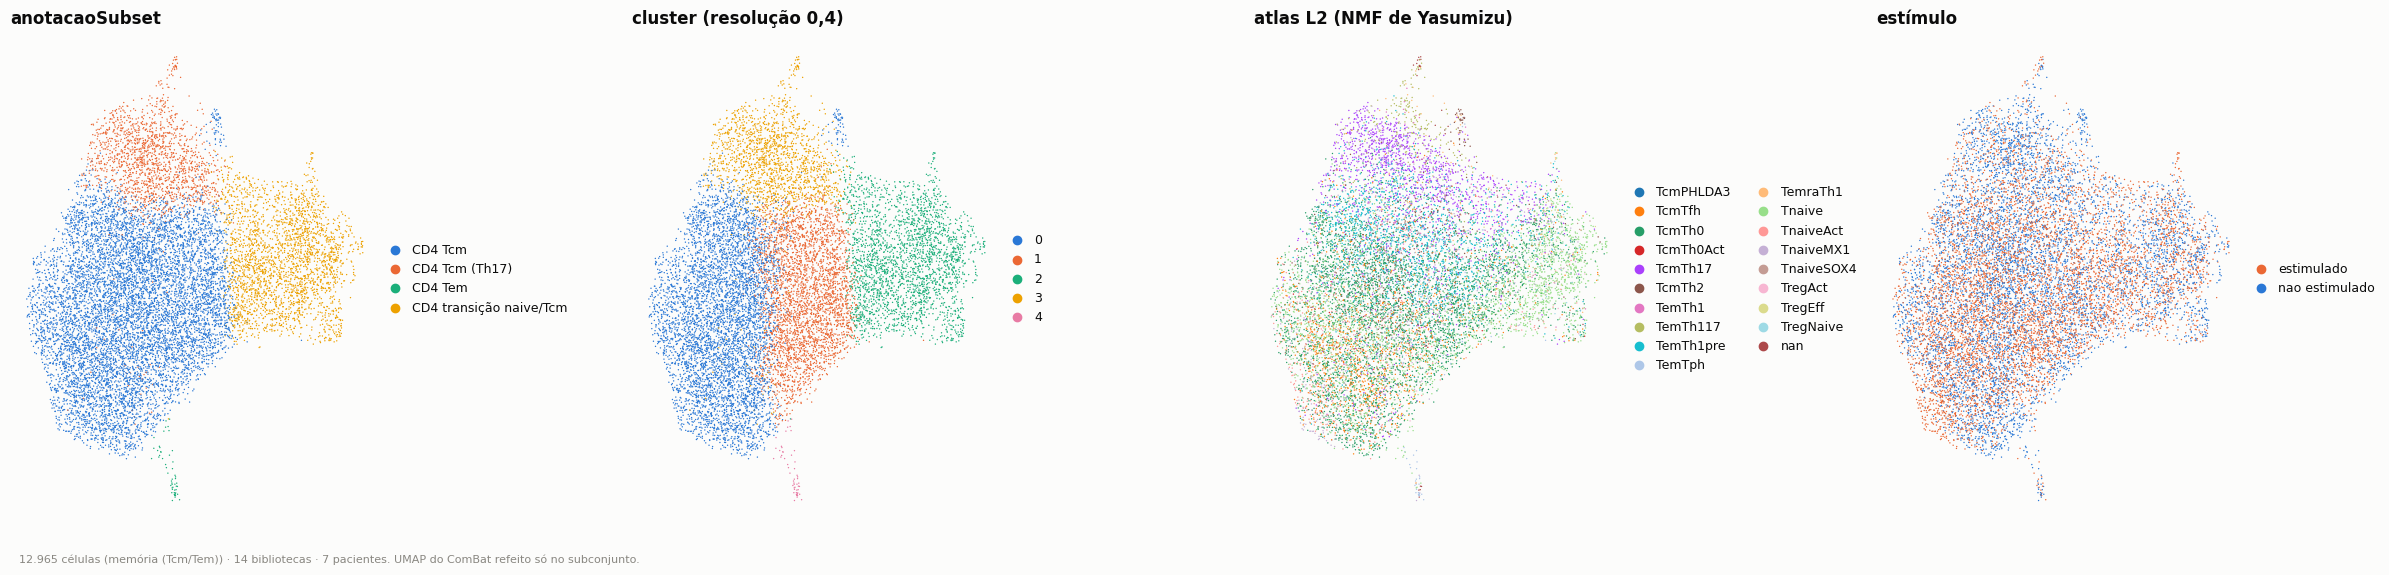

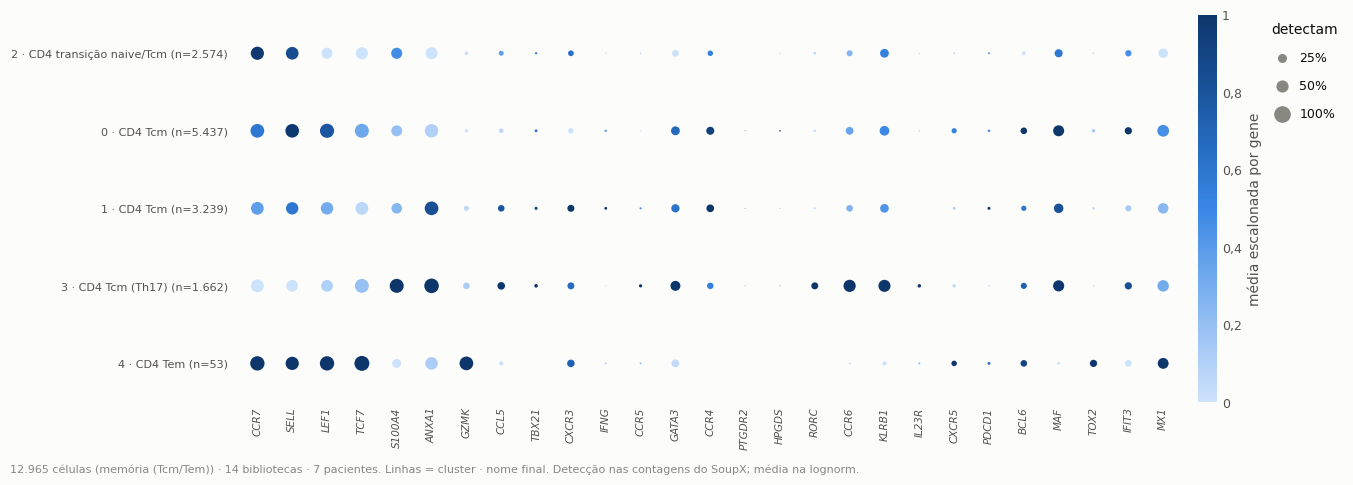

In [8]:
ORD_M = sorted(set(nomes.values()), key=lambda s: (["CD4 transição", "CD4 Tcm", "CD4 Tem", "CD4 Temra"].index(
    next((p for p in ["CD4 transição", "CD4 Temra", "CD4 Tem", "CD4 Tcm"] if s.startswith(p)), "CD4 Tcm")), s))
fig_umap_dot(RM, "memória (Tcm/Tem)", ["CCR7", "SELL", "LEF1", "TCF7", "S100A4", "ANXA1", "GZMK", "CCL5", "TBX21", "CXCR3", "IFNG",
                                       "CCR5", "GATA3", "CCR4", "PTGDR2", "HPGDS", "RORC", "CCR6", "KLRB1", "IL23R", "CXCR5", "PDCD1",
                                       "BCL6", "MAF", "TOX2", "IFIT3", "MX1"], ORD_M)

## 3. `anotacaoSubset` de todas as CD4

- Treg: o estado do P10.
- Naive e memória: os nomes acima.
- CD4 ativada, ativada (Th17) e citotóxica (Temra): a `anotacao`.

A UMAP é a das 30.933 CD4 do P09 (ComBat só nas CD4).

In [9]:
sub = io.load_data("P10_treg_subset", "anotacao_subset").set_index("cell_key")
keys = cd4.obs["cell_key"].astype(str).to_numpy()
final = sub["anotacaoSubset"].reindex(keys).astype(object)
for R in (RN, RM):
    s = pd.Series(R["b"].obs["anotacaoSubset"].astype(str).to_numpy(), index=R["b"].obs["cell_key"].astype(str).to_numpy())
    final.loc[s.index] = s.to_numpy()
assert final.notna().all()
cd4.obs["anotacaoSubset"] = final.to_numpy()
cont = pd.crosstab(cd4.obs["anotacaoSubset"], cd4.obs["anotacao"].astype(str))
io.save_table(cont, NB, "anotacaoSubset_x_anotacao", description="anotacaoSubset × anotacao (contagens)")
display(cd4.obs["anotacaoSubset"].value_counts().to_frame("células"))

,células
anotacaoSubset,
CD4 naive,10170
CD4 Tcm,8676
CD4 ativada,2798
CD4 transição naive/Tcm,2574
CD4 Tcm (Th17),1662
CD4 naive IFN⁺,1540
CD4 citotóxica (Temra),1321
eTreg,735
Treg naive,569


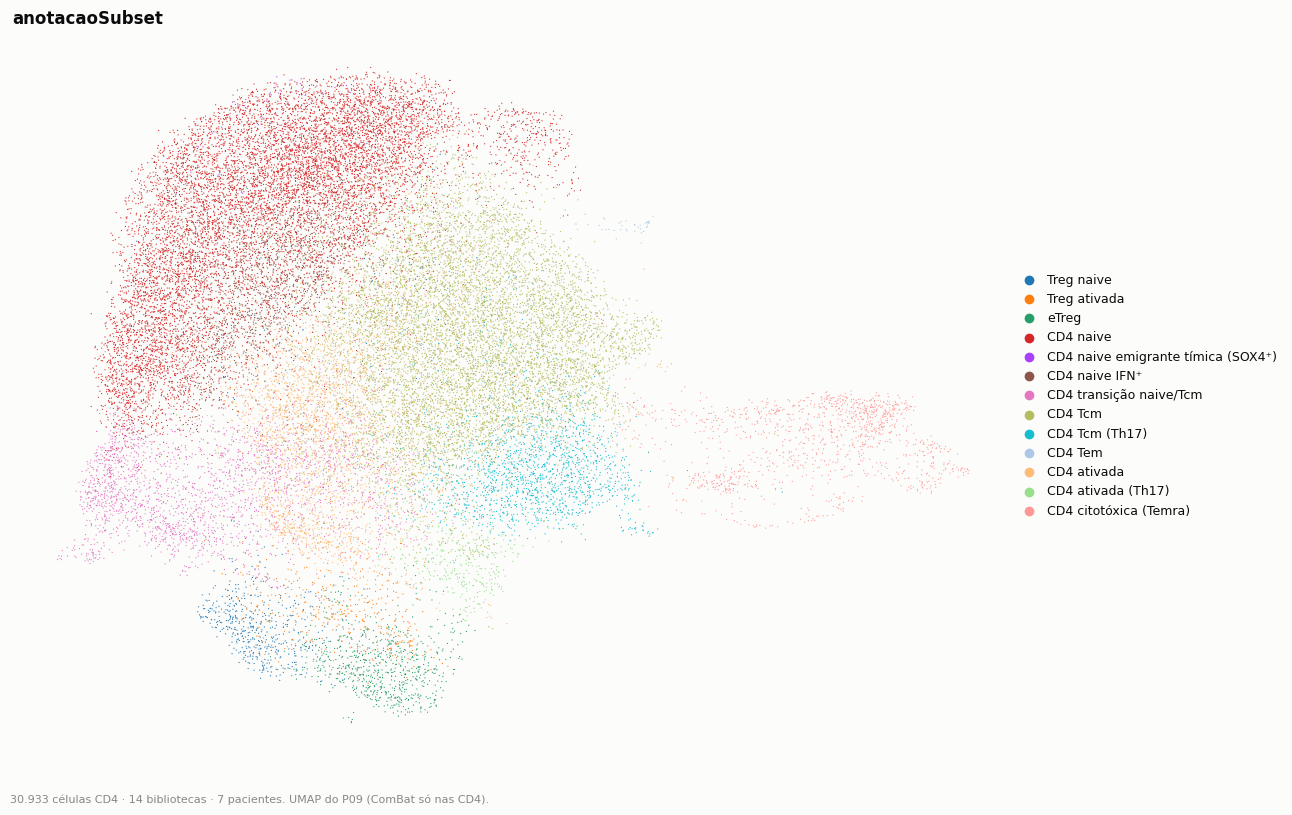

In [10]:
d9 = io.load_data("P09_cd4_limpo", "cd4_limpo", "h5ad")
assert (d9.obs["cell_key"].astype(str).to_numpy() == keys).all()
cd4.obsm["X_umap"] = np.asarray(d9.obsm["X_umap"])
ORD_ALL = [n for n in (["Treg naive", "Treg ativada", "eTreg"] + ORD_N + ORD_M) if n in set(final)] + \
          [n for n in an.LABEL_ORDER if n in set(final) and n not in ORD_N + ORD_M]
ORD_ALL += [n for n in sorted(set(final)) if n not in ORD_ALL]
cd4.obs["anotacaoSubset"] = pd.Categorical(final.to_numpy(), categories=ORD_ALL)
fig, ax = plt.subplots(figsize=(13, 8))
sc.pl.umap(cd4, color="anotacaoSubset", ax=ax, show=False, frameon=False, size=3, title="anotacaoSubset",
           palette=sc.pl.palettes.default_102[:len(ORD_ALL)] if len(ORD_ALL) > 20 else None)
plotting.note(fig, f"{F.n(N_CD4)} células CD4 · {plotting.N_DESIGN}. UMAP do P09 (ComBat só nas CD4).", y=0.0)
fig.tight_layout(rect=(0, 0.03, 1, 1))
plotting.savefig(fig, NB, "umap_anotacaoSubset", description="UMAP das CD4 pela anotacaoSubset",
                 data=pd.DataFrame({"cell_key": keys, "anotacaoSubset": final.to_numpy(),
                                    "umap1": cd4.obsm["X_umap"][:, 0], "umap2": cd4.obsm["X_umap"][:, 1]}), data_index=False)
plt.show()

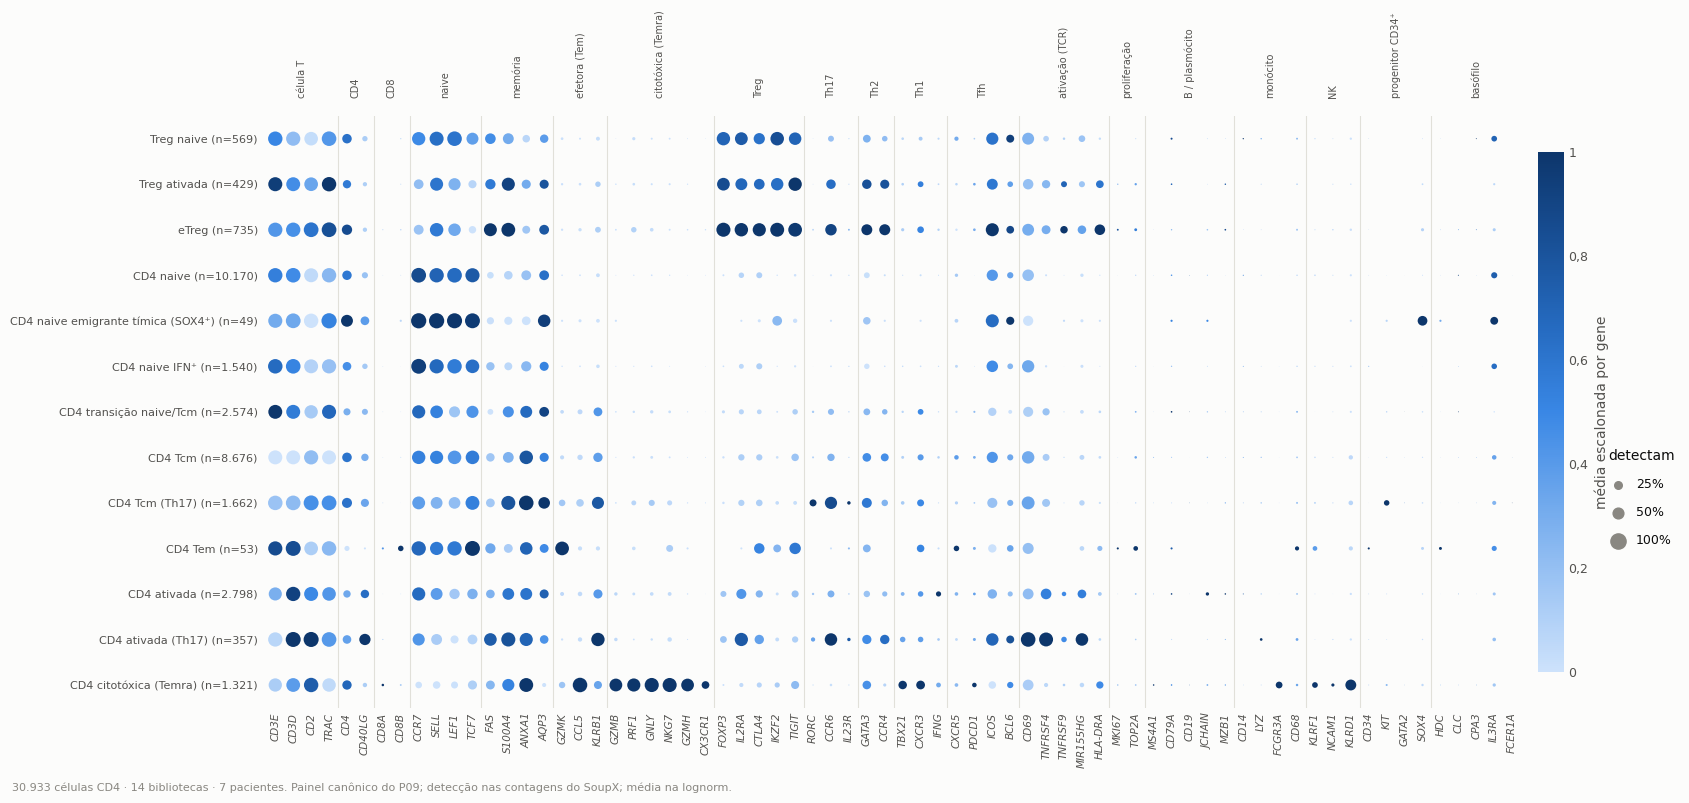

In [11]:
cd4.X = __import__("functions.pipeline", fromlist=["lognorm"]).lognorm(cd4.layers["counts"])
genes = [g for g in an.panel_genes() if g in cd4.var_names]
frac, mean = an.dot_stats(cd4, cd4.obs["anotacaoSubset"], genes)
n_t = cd4.obs["anotacaoSubset"].astype(str).value_counts()
grupos_col = [(t, len([g for g in gs if g in cd4.var_names])) for t, (gs, _) in an.PANEL.items()]
fig, ax = plt.subplots(figsize=(17, 0.36 * len(ORD_ALL) + 3.2))
sc_ = an.dotplot(ax, frac, mean, rows=ORD_ALL, cols=genes, groups_of_cols=grupos_col)
ax.set_yticklabels([f"{t} (n={F.n(n_t[t])})" for t in ORD_ALL])
cb = fig.colorbar(sc_, ax=ax, fraction=0.02, pad=0.01)
cb.set_label("média escalonada por gene")
plotting._style_colorbar(cb)
for v in (0.25, 0.5, 1.0):
    ax.scatter([], [], s=v * 120, c=INK["muted"], label=F.pct(v, 0))
ax.legend(title="detectam", loc="upper left", bbox_to_anchor=(1.06, 0.45), frameon=False, labelspacing=1.2)
plotting.note(fig, f"{F.n(N_CD4)} células CD4 · {plotting.N_DESIGN}. Painel canônico do P09; detecção nas contagens do SoupX; "
                   "média na lognorm.", y=0.0)
fig.tight_layout()
plotting.savefig(fig, NB, "painel_anotacaoSubset", description="Marcadores canônicos por tipo da anotacaoSubset",
                 data=(frac * 100).round(1).reindex(ORD_ALL).rename_axis("anotacaoSubset").reset_index(), data_index=False)
plt.show()

## 4. Saídas

- `anotacao_subset.parquet`: `cell_key`, `anotacao`, `anotacaoSubset` das 30.933 CD4 limpas.
- `naive_subset.h5ad` e `memoria_subset.h5ad`: deltas de cada subconjunto (cluster, nome,
  embedding e UMAP).

In [12]:
for R in (RN, RM):
    b = R["b"]
    out = ad.AnnData(X=sp.csr_matrix((b.n_obs, 0), dtype=np.float32),
                     obs=pd.DataFrame({"cell_key": b.obs["cell_key"].astype(str).to_numpy(),
                                       "cluster": b.obs["cluster"].astype(str).to_numpy(),
                                       "anotacaoSubset": b.obs["anotacaoSubset"].astype(str).to_numpy()}, index=b.obs_names))
    out.obsm["X_emb_combat"] = b.obsm["X_emb"]
    out.obsm["X_umap"] = np.asarray(b.obsm["X_umap"], np.float32)
    out.uns["subset"] = {"resolucao": R["res"], "k_min": R["k_min"], "hvg": R["info"]["hvg"], "nomes": R["nomes"]}
    print(io.save_data(out, NB, f"{R['slug']}_subset", description=f"Delta do subconjunto {R['slug']}: cluster, nome, UMAP"))
tab_final = pd.DataFrame({"cell_key": keys, "anotacao": cd4.obs["anotacao"].astype(str).to_numpy(),
                          "anotacaoSubset": final.to_numpy()})
print(io.save_data(tab_final, NB, "anotacao_subset", description="anotacaoSubset de todas as CD4 limpas (Treg do P10, naive e memória do P11)"))

[io] inalterado, não regravado: naive_subset.h5ad
/mnt/SATA/singleCellTaru/dataReseq/P11_naive_memoria_subset/naive_subset.h5ad
[io] inalterado, não regravado: memoria_subset.h5ad
/mnt/SATA/singleCellTaru/dataReseq/P11_naive_memoria_subset/memoria_subset.h5ad
[io] conteúdo mudou — nova versão: anotacao_subset__v2.parquet (anterior preservada)
/mnt/SATA/singleCellTaru/dataReseq/P11_naive_memoria_subset/anotacao_subset__v2.parquet


## 5. Interpretação

**Naive (11.759 células).** A regra escolheu a resolução 1,0: 9 clusters, ARI entre sementes
0,65 e 72 % das células em clusters estáveis. A concordância com a NMF é baixa em qualquer
resolução (ARI ≤ 0,15): a naive é um contínuo.
- Saem dois estados com as duas fontes de acordo:
  - **IFN⁺** (cluster 3, 1.540 células): 65 % TnaiveMX1 no atlas e IFIT3/MX1 altos (z 2,6);
  - **emigrante tímica SOX4⁺** (cluster 8, 49 células): 83 % TnaiveSOX4 e z 2,8.
- **Naive ativada não sai, porque as fontes discordam.** O cluster 4 (86 % ML) é 49 % TnaiveAct
  no atlas, mas tem o escore de genes precoces de ativação abaixo da média (z −0,8). Já o
  cluster 1 tem esse escore alto (z 2,0), mas só 12 % TnaiveAct. O painel de "ativada" (CD69,
  NFKBIA, MIR155HG, TNFAIP3, IER2, JUNB) não mede o mesmo que o TnaiveAct do atlas.

**Memória (12.965 células).** A regra escolheu a resolução 0,4: 5 clusters, ARI 0,60. A
estabilidade é parecida em todas as resoluções de 0,4 a 1,5 (0,53–0,60), então os clusters
finos não são mais instáveis que os grossos.
- **(Th17)** sai no cluster 3 (69 % TcmTh17 no atlas; RORC, CCR6, KLRB1, IL23R altos; z 1,8).
- **(Th1) quase sai no cluster 1:** 24 % de tipos Th1 no atlas (TemTh1pre), com CXCR3, TBX21 e
  CCL5 altos (z 1,06), mas fica abaixo do limiar de 25 %.
- **(Th2) não sai.** O TcmTh2 do atlas é raro aqui (3 % da memória e ≤ 5 % em qualquer cluster).
  GATA3 e CCR4 sobem nos clusters 0 e 1, junto com os marcadores Tfh (MAF, BCL6), sem um cluster
  Th2 separado.
- **CD4 Tem** (cluster 4, 53 células) é o antigo "Tem GZMK⁺": GZMK alto e CCR7/TCF7 também altos.
  No atlas é 56 % TemTph, mas o escore Tfh/Tph fica abaixo da média.

**Limites.** Os sufixos dependem de um limiar fixado antes (atlas ≥ 25 %). Numa resolução mais
fina a memória pode separar Th1 e Th2. Os nomes não foram validados por citometria.

## Problemas encontrados

In [13]:
log.add("INFO", "sufixos de helper", "os sufixos (Th1)/(Th2)/(Th17)/(Tfh) exigem atlas ≥ 25 % e z do painel > 0",
        evidence="regra fixada no cabeçalho, antes de ver os clusters",
        impact="clusters de memória com perfil misto ficam sem sufixo",
        recommendation="confirmar Th1/Th2 por citocinas após reestímulo ou por citometria (CXCR3/CCR4/CCR6)")
show(log.save())

severity,location,problem,evidence,impact,recommendation
INFO,sufixos de helper,os sufixos (Th1)/(Th2)/(Th17)/(Tfh) exigem atlas ≥ 25 % e z do painel > 0,"regra fixada no cabeçalho, antes de ver os clusters",clusters de memória com perfil misto ficam sem sufixo,confirmar Th1/Th2 por citocinas após reestímulo ou por citometria (CXCR3/CCR4/CCR6)
